# Sentence-level Cross-lingual Rank Agreement

**Feeds:** RQ2, as a robustness check on notebook 05.

Notebook 05 establishes, at document level, that per-document difficulty carries
across the two language versions: the same articles are hard in Portuguese and in
its English translation. That result is measured on one query per article. This
notebook asks whether the same relationship survives when the task is decomposed,
which is a genuine test rather than a formality -- the sentence-level regime
queries the model three times per sentence, in separate detection, extraction and
classification stages, and only then aggregates back to the document. If document
difficulty were an artefact of asking for a whole article in one go, the rank
agreement should weaken or disappear under decomposition.

**Scope.** The sentence-level experiment runs a single model, `qwen3_14b`, at a
fixed temperature of 0.3, in both languages, under two prompt conditions:
`sent_exp` (one-shot example only) and `sent_def_exp` (example plus the
definition of narrative participant, with self-reported confidences). Both are
included, alongside the same model's document-level run as the reference point.

Scores are read from `results/sentence_level/cls/`, the output of the full
three-stage pipeline, and are strict span-level F1 throughout.

In [1]:
import sys

sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import _common as c

CONDITION_COLORS = {
    "document-level": "#999999",
    "sent_exp": "#0072B2",
    "sent_def_exp": "#D55E00",
}
MODEL = "qwen3_14b"

In [2]:
def per_document_counts(df: pd.DataFrame, group_cols) -> pd.DataFrame:
    """Span-level tp/fp/fn and P/R/F1 per group x document.

    Same construction as notebook 05, kept local so that this notebook can be
    run on its own.
    """
    counts = (
        df.groupby(list(group_cols) + ["result"])
        .size()
        .unstack("result")
        .reindex(columns=["tp", "fp", "fn"])
        .fillna(0.0)
        .reset_index()
    )
    denom_p = (counts["tp"] + counts["fp"]).replace(0, np.nan)
    denom_r = (counts["tp"] + counts["fn"]).replace(0, np.nan)
    counts["precision"] = (counts["tp"] / denom_p).fillna(0.0)
    counts["recall"] = (counts["tp"] / denom_r).fillna(0.0)
    denom_f1 = (counts["precision"] + counts["recall"]).replace(0, np.nan)
    counts["f1"] = (2 * counts["precision"] * counts["recall"] / denom_f1).fillna(0.0)
    return counts


# --- sentence-level -------------------------------------------------------
sent = pd.concat(
    [c.load_detailed("sentence_level/cls", lang) for lang in c.LANGUAGE_ORDER],
    ignore_index=True,
)
sent = c.add_run_config_columns(sent)
sent["condition"] = "sent_" + sent["base_template"].str.split("_", n=1).str[1]

sent_doc = per_document_counts(sent, ["condition", "language", "doc_id"])

# --- document-level reference --------------------------------------------
best_configs = c.load_best_configs()
doc = pd.concat([c.load_detailed("test", lang) for lang in c.LANGUAGE_ORDER], ignore_index=True)
doc = c.filter_to_best_configs(doc, best_configs, verbose=False)
doc = doc[doc["model"] == MODEL].copy()
doc["condition"] = "document-level"
doc_doc = per_document_counts(doc, ["condition", "language", "doc_id"])

per_doc = pd.concat([doc_doc, sent_doc], ignore_index=True)
CONDITIONS = ["document-level", "sent_exp", "sent_def_exp"]
print()
print(per_doc.groupby(["condition", "language"])["doc_id"].nunique().to_string())


condition       language  
document-level  english       96
                portuguese    97
sent_def_exp    english       96
                portuguese    97
sent_exp        english       96
                portuguese    97


## Pairing and per-document scores

The pairing is the same as in notebook 05 and is re-derived here rather than
imported: the documents present in both language versions, intersected across
every condition so that all three panels of the figure below describe exactly the
same set of articles.

In [3]:
paired = (
    per_doc.pivot_table(index=["condition", "doc_id"], columns="language", values="f1")
    .dropna(subset=c.LANGUAGE_ORDER)
    .reset_index()
)

# Keep only documents scored under every condition, so the panels are comparable.
counts_per_doc = paired.groupby("doc_id")["condition"].nunique()
SHARED_DOCS = sorted(counts_per_doc[counts_per_doc == len(CONDITIONS)].index)
paired = paired[paired["doc_id"].isin(SHARED_DOCS)]

print(f"documents scored under all {len(CONDITIONS)} conditions in both languages: {len(SHARED_DOCS)}")
print()
summary = (
    paired.groupby("condition")[c.LANGUAGE_ORDER].mean()
    .reindex(CONDITIONS)
    .rename(columns={"portuguese": "mean_f1_pt", "english": "mean_f1_en"})
)
summary["mean_delta_en_minus_pt"] = summary["mean_f1_en"] - summary["mean_f1_pt"]
summary.round(4)

documents scored under all 3 conditions in both languages: 96



language,mean_f1_pt,mean_f1_en,mean_delta_en_minus_pt
condition,,,
document-level,0.3297,0.3259,-0.0038
sent_exp,0.4529,0.4291,-0.0238
sent_def_exp,0.4431,0.3936,-0.0496


## Does the rank agreement survive decomposition?

The figure repeats notebook 05's rank-rank construction, once per condition. Each
document is placed by its **rank** under Portuguese against its **rank** under
English, rank 1 being the document the model scored lowest on, with ties averaged
exactly as Spearman averages them. Points along the diagonal mean the two
versions order the documents the same way.

The leftmost panel is the document-level run of the same model, carried over from
notebook 05, so the two sentence-level panels are read against it rather than
against nothing.

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\07_sentence_level_rank_agreement.pdf


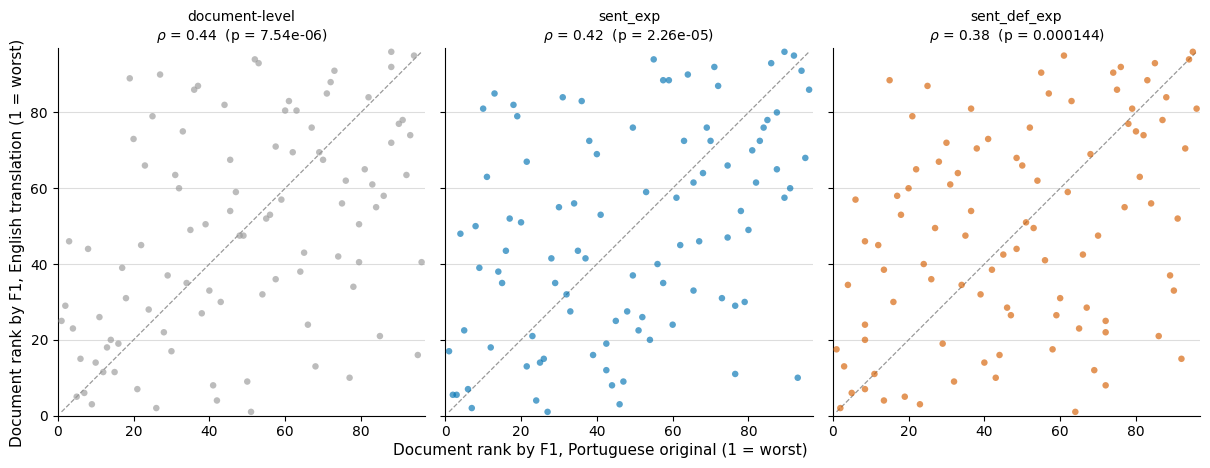

,spearman_rho,p_value,n_docs,mean_f1_pt,mean_f1_en
condition,,,,,
document-level,0.4393,0.0000,96,0.3297,0.3259
sent_exp,0.4180,0.0000,96,0.4529,0.4291
sent_def_exp,0.3783,0.0001,96,0.4431,0.3936


In [4]:
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(4.1 * len(CONDITIONS), 4.4),
                         sharex=True, sharey=True)

rho_rows = []
for ax, condition in zip(np.atleast_1d(axes), CONDITIONS):
    sub = paired[paired["condition"] == condition]
    rank_pt = sub["portuguese"].rank(method="average")
    rank_en = sub["english"].rank(method="average")
    rho, p_value = stats.spearmanr(sub["portuguese"], sub["english"])
    rho_rows.append({
        "condition": condition,
        "spearman_rho": rho,
        "p_value": p_value,
        "n_docs": len(sub),
        "mean_f1_pt": sub["portuguese"].mean(),
        "mean_f1_en": sub["english"].mean(),
    })

    n = len(sub)
    ax.plot([1, n], [1, n], color="#999999", linewidth=0.9, linestyle="--", zorder=2)
    ax.scatter(rank_pt, rank_en, s=22, alpha=0.65, zorder=3,
               color=CONDITION_COLORS[condition], edgecolor="none")
    ax.set_title(f"{condition}\n" + r"$\rho$ = " + f"{rho:.2f}  (p = {p_value:.3g})", fontsize=10)
    ax.set_xlim(0, n + 1)
    ax.set_ylim(0, n + 1)
    ax.set_aspect("equal", adjustable="box")
    c.style_axis(ax)

fig.supxlabel("Document rank by F1, Portuguese original (1 = worst)", fontsize=11)
fig.supylabel("Document rank by F1, English translation (1 = worst)", fontsize=11)
c.save_fig(fig, "07_sentence_level_rank_agreement")
plt.show()

rho_table = pd.DataFrame(rho_rows).set_index("condition").reindex(CONDITIONS)
rho_table.round(4)

## Is either language favoured under decomposition?

The rank agreement above speaks only to ordering. The paired differences below
speak to level, and answer the RQ4 question within the sentence-level regime:
having decomposed the task, does the English translation now do better than the
Portuguese original, or does the null result of notebook 05 hold here too?

In [5]:
rows = []
for condition in CONDITIONS:
    sub = paired[paired["condition"] == condition]
    differences = (sub["english"] - sub["portuguese"]).to_numpy()
    p_value = np.nan if np.allclose(differences, 0) else stats.wilcoxon(differences).pvalue
    rows.append({
        "condition": condition,
        "mean_d_doc_f1": differences.mean(),
        "median_d_doc_f1": np.median(differences),
        "wilcoxon_p": p_value,
        "favours": "English" if differences.mean() > 0 else "Portuguese",
        "n_docs": differences.size,
    })

pd.DataFrame(rows).set_index("condition").round(4)

,mean_d_doc_f1,median_d_doc_f1,wilcoxon_p,favours,n_docs
condition,,,,,
document-level,-0.0038,0.0051,0.9408,Portuguese,96
sent_exp,-0.0238,-0.0321,0.0492,Portuguese,96
sent_def_exp,-0.0496,-0.0473,0.0005,Portuguese,96


## Synthesis

- Feeds **RQ2** as a robustness check, and returns two findings for RQ3 and RQ4 that
  were not what the check was looking for.

- **The rank agreement survives decomposition.** `qwen3_14b` scores rho = 0.44 at
  document level, 0.42 under `sent_exp` and 0.38 under `sent_def_exp`, every one
  significant at p < 0.001. The three values are of the same magnitude, so the
  cross-lingual agreement reported in notebook 05 is **not an artefact of querying a
  whole article at once**: the same articles remain hard in both language versions
  even when the model is asked one sentence at a time, in separate detection,
  extraction and classification stages. This is the answer to the question this
  notebook was built for.

- **Decomposition raises absolute performance substantially.** Mean per-document F1
  rises from 0.330 at document level to 0.453 under `sent_exp` in Portuguese, and
  from 0.326 to 0.429 in English -- roughly twelve and ten F1 points respectively,
  for the same model at the same temperature. Restricting the input to one sentence
  and separating the stages is worth more than any prompt-content choice observed at
  document level. This belongs to the sentence-level bottleneck analysis rather than
  here, but it is the largest effect visible in this notebook.

- **Under decomposition the translation is no longer merely unhelpful, it is worse.**
  At document level the paired difference is -0.004 and not significant (p = 0.94),
  the null result of notebook 05. Under `sent_exp` it is -0.024 (p = 0.049) and under
  `sent_def_exp` -0.050 (p = 0.0005), both favouring the Portuguese original. So the
  more the task is decomposed, the clearer the Portuguese advantage becomes, which
  strengthens rather than qualifies the RQ4 conclusion.

- **Adding the definition costs English more than Portuguese.** Moving from
  `sent_exp` to `sent_def_exp` lowers Portuguese by about 0.010 F1 but English by
  about 0.036, and simultaneously lowers the rank agreement from 0.42 to 0.38. The
  extra prompt material is not language-neutral in its effect.

- **Scope caveat.** This is one model at one temperature, so it bounds the generality
  of the document-level finding rather than establishing it independently. It is a
  consistency check, not a second experiment.
- **Metric caveat.** Only strict span-level F1 is used here. The sentence-level
  `results.csv` predates the corrected relaxed metric and carries a single `f1_r`
  column rather than the `f1_r_micro`/`f1_r_macro` pair the test stage now reports,
  so relaxed scores are not comparable across the two regimes and are deliberately
  not used. Strict F1 is computed here from `detailed_results.csv` in both regimes
  by identical code, so it is comparable.